여러분은 왜 개 사료가 예상보다 빨리 상하게 되는지를 파악하기위해 개 사료 회사에 고용되었습니다. 안 좋은 소식은 이 회사는 한동안 장비를 업그레이드 하지 않았습니다. 즉, 이 회사에서 사용하는 5가지 방부제의 사용 용량이 중구난방이라는 뜻입니다. 하지만 그 중에서 가장 많은 영향을 끼치는 것이 무엇일까요?<br>
이 회사에서는 먼저 4가지 방부제(A, B, C, D)가 함유된 방부제 묶음을 섞은 뒤 '필러'라는 화학물질로 마무리합니다. 식품과학자들은 A, B, C, D 방부제 중 하나가 문제를 일으키고 있다고 생각하지만, 그게 어떤 것인지 명확하게 하기위해 여러분이 고용됐습니다. "랜덤포레스트"로 어떤 방부제가 사료를 빨리 상하게 하는지 찾아보세요!

- Pres_A : 혼합물의 A비율
- Pres_B : 혼합물의 B비율
- Pres_C : 혼합물의 C비율
- Pres_D : 혼합물의 D비율
- Spoiled : 개 사료가 상했는지 여부를 나타내는 레이블.

**시나리오에서 요구하는 바를 고려하여, 머신러닝을 이용해서 문제를 풀어보세요.**

In [94]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.tree import plot_tree
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [4]:
df = pd.read_csv("./과제/랜덤포레스트/dog_food.csv")

In [5]:
df.head()

,A,B,C,D,Spoiled
0,4,2,12.0,3,1.0
1,5,6,12.0,7,1.0
2,6,2,13.0,6,1.0
3,4,2,12.0,1,1.0
4,4,2,12.0,3,1.0


In [6]:
df.shape

(490, 5)

In [7]:
df.dtypes

A            int64
B            int64
C          float64
D            int64
Spoiled    float64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490 entries, 0 to 489
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   A        490 non-null    int64  
 1   B        490 non-null    int64  
 2   C        490 non-null    float64
 3   D        490 non-null    int64  
 4   Spoiled  490 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 19.3 KB


In [9]:
df.describe()

,A,B,C,D,Spoiled
count,490.000000,490.000000,490.000000,490.000000,490.000000
mean,5.534694,5.504082,9.126531,5.579592,0.285714
std,2.951520,2.853797,2.055545,2.854837,0.452216
min,1.000000,1.000000,5.000000,1.000000,0.000000
25%,3.000000,3.000000,8.000000,3.000000,0.000000
50%,5.000000,6.000000,9.000000,6.000000,0.000000
75%,8.000000,8.000000,11.000000,8.000000,1.000000
max,10.000000,10.000000,14.000000,10.000000,1.000000


In [10]:
df["total"] = df.drop("Spoiled", axis = 1).sum(axis = 1)

In [11]:
df["Pres_A"] = df["A"] / df["total"]
df["Pres_B"] = df["B"] / df["total"]
df["Pres_C"] = df["C"] / df["total"]
df["Pres_D"] = df["D"] / df["total"]

In [12]:
df.head()

,A,B,C,D,Spoiled,total,Pres_A,Pres_B,Pres_C,Pres_D
0,4,2,12.0,3,1.0,21.0,0.190476,0.095238,0.571429,0.142857
1,5,6,12.0,7,1.0,30.0,0.166667,0.200000,0.400000,0.233333
2,6,2,13.0,6,1.0,27.0,0.222222,0.074074,0.481481,0.222222
3,4,2,12.0,1,1.0,19.0,0.210526,0.105263,0.631579,0.052632
4,4,2,12.0,3,1.0,21.0,0.190476,0.095238,0.571429,0.142857


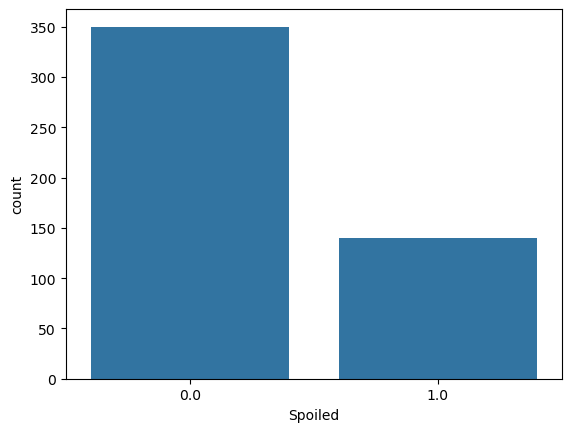

In [13]:
sns.countplot(data = df, x = "Spoiled")

plt.show()

In [14]:
df["Spoiled"].value_counts()

Spoiled
0.0    350
1.0    140
Name: count, dtype: int64

- total 과 Spoiled 의 관계, 각 방부제와 Spoiled 의 관계 파악하기

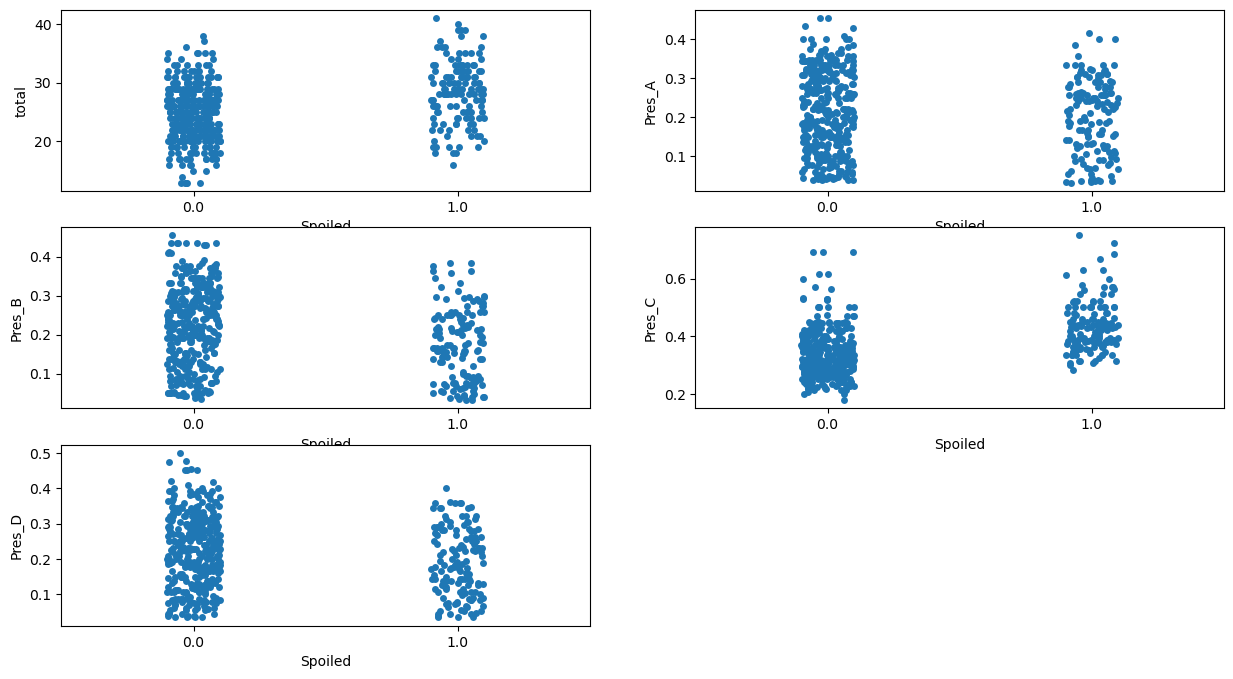

In [15]:
fig = plt.figure(figsize = (15, 8))
ax1 = fig.add_subplot(3, 2, 1)
ax2 = fig.add_subplot(3, 2, 2)
ax3 = fig.add_subplot(3, 2, 3)
ax4 = fig.add_subplot(3, 2, 4)
ax5 = fig.add_subplot(3, 2, 5)

sns.stripplot(y = 'total', x = "Spoiled", data = df, ax = ax1)
sns.stripplot(y = 'Pres_A', x = "Spoiled", data = df, ax = ax2)
sns.stripplot(y = 'Pres_B', x = "Spoiled", data = df, ax = ax3)
sns.stripplot(y = 'Pres_C', x = "Spoiled", data = df, ax = ax4)
sns.stripplot(y = 'Pres_D', x = "Spoiled", data = df, ax = ax5)

plt.show()

- 사료가 상한 경우 (Spoiled == 1)
    - total, 방부제 C가 높게 분포되어 있음
    - 반면에 방부제 A, B, D는 비교적 낮게 분포되어 있음

- total값이 Spoiled 여부에 영향을 끼칠 것 같지만, A ~ D 중 가장 큰 영향을 주는 방부제를 찾는 거니까 비율에만 집중하자

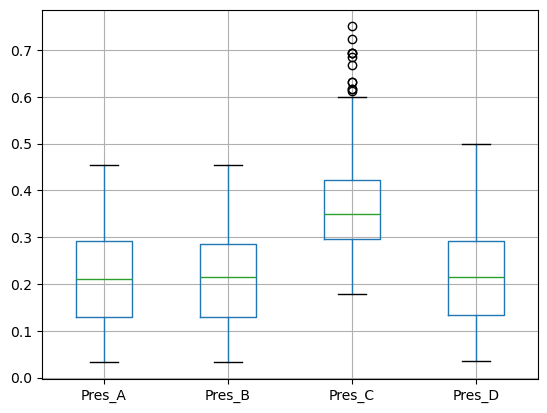

In [16]:
df.loc[:, "Pres_A" : "Pres_D"].boxplot()

plt.show()

- 방부제 A, B, D 비율의 분포는 유사한 반면에, 방부제 C의 비율은 비교적 높게 분포해 있으며 상단에 이상치도 많이 보임.

## 모델 훈련

In [17]:
df.columns

Index(['A', 'B', 'C', 'D', 'Spoiled', 'total', 'Pres_A', 'Pres_B', 'Pres_C',
       'Pres_D'],
      dtype='object')

In [18]:
x = df.loc[:, "Pres_A":"Pres_D"]
y = df["Spoiled"]

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, 
                                                    random_state = 26)

In [20]:
x_train.shape, x_test.shape

((392, 4), (98, 4))

In [21]:
rf = RandomForestClassifier(n_jobs = -1, random_state = 26)

In [22]:
scores = cross_validate(rf, x_train, y_train, return_train_score = True, n_jobs = -1)

In [23]:
print(np.mean(scores["train_score"]), np.mean(scores["test_score"]), np.mean(scores["fit_time"]))

0.997448159378116 0.762739370334307 0.19789209365844726


- 훈련데이터와 테스트데이터의 score 값 차이가 크고 훈련데이터의 score 값이 매우 높아 과대적합이 의심됨.
    - max_depth 옵션 추가하기

In [39]:
rf = RandomForestClassifier(n_jobs = -1, random_state = 26, max_depth = 5)

In [40]:
scores = cross_validate(rf, x_train, y_train, return_train_score = True, n_jobs = -1)

In [41]:
print(np.mean(scores["train_score"]), np.mean(scores["test_score"]), np.mean(scores["fit_time"]))

0.8998595877169777 0.7779941577409931 0.20688157081604003


- 그리드서치 활용하여 max_depth, min_impurity_decrease, min_samples_split 최적값 찾기

In [27]:
params = {"max_depth" : range(3, 20)}

In [28]:
gs = GridSearchCV(RandomForestClassifier(random_state = 26), params, n_jobs = -1)
gs.fit(x_train, y_train)

GridSearchCV(estimator=RandomForestClassifier(random_state=26), n_jobs=-1,
             param_grid={'max_depth': range(3, 20)})

In [29]:
# 최상의 매개변수 조합
gs.best_params_

{'max_depth': 10}

In [30]:
# 최상의 교차 검증 점수
np.max(gs.cv_results_["mean_test_score"])

0.7780266147354755

In [31]:
rf = RandomForestClassifier(n_jobs = -1, random_state = 26, max_depth = 10)

In [32]:
scores = cross_validate(rf, x_train, y_train, return_train_score = True, n_jobs = -1)

In [33]:
print(np.mean(scores["train_score"]), np.mean(scores["test_score"]), np.mean(scores["fit_time"]))

0.9961742740277975 0.7780266147354755 0.21715717315673827


- max_depth = 10 으로 설정했을 때 테스트용 score 가 약간 더 높게 나오긴 했으나, 훈련용 score와 편차가 커 과대적합이 의심됨
    - 최종 max_depth = 5

- 과대적합이 의심되어 max_depth 옵션을 추가
    - 훈련용데이터와 테스트용데이터의 정확도 편차 감소
    - 테스트용 정확도 약간 상승

In [42]:
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=5, n_jobs=-1, random_state=26)

In [43]:
rf.feature_importances_

array([0.20167254, 0.18303706, 0.46876839, 0.14652201])

- Pred_C 가 가장 많은 영향을 미치는 것으로 보임 

In [36]:
len(rf.estimators_)

100

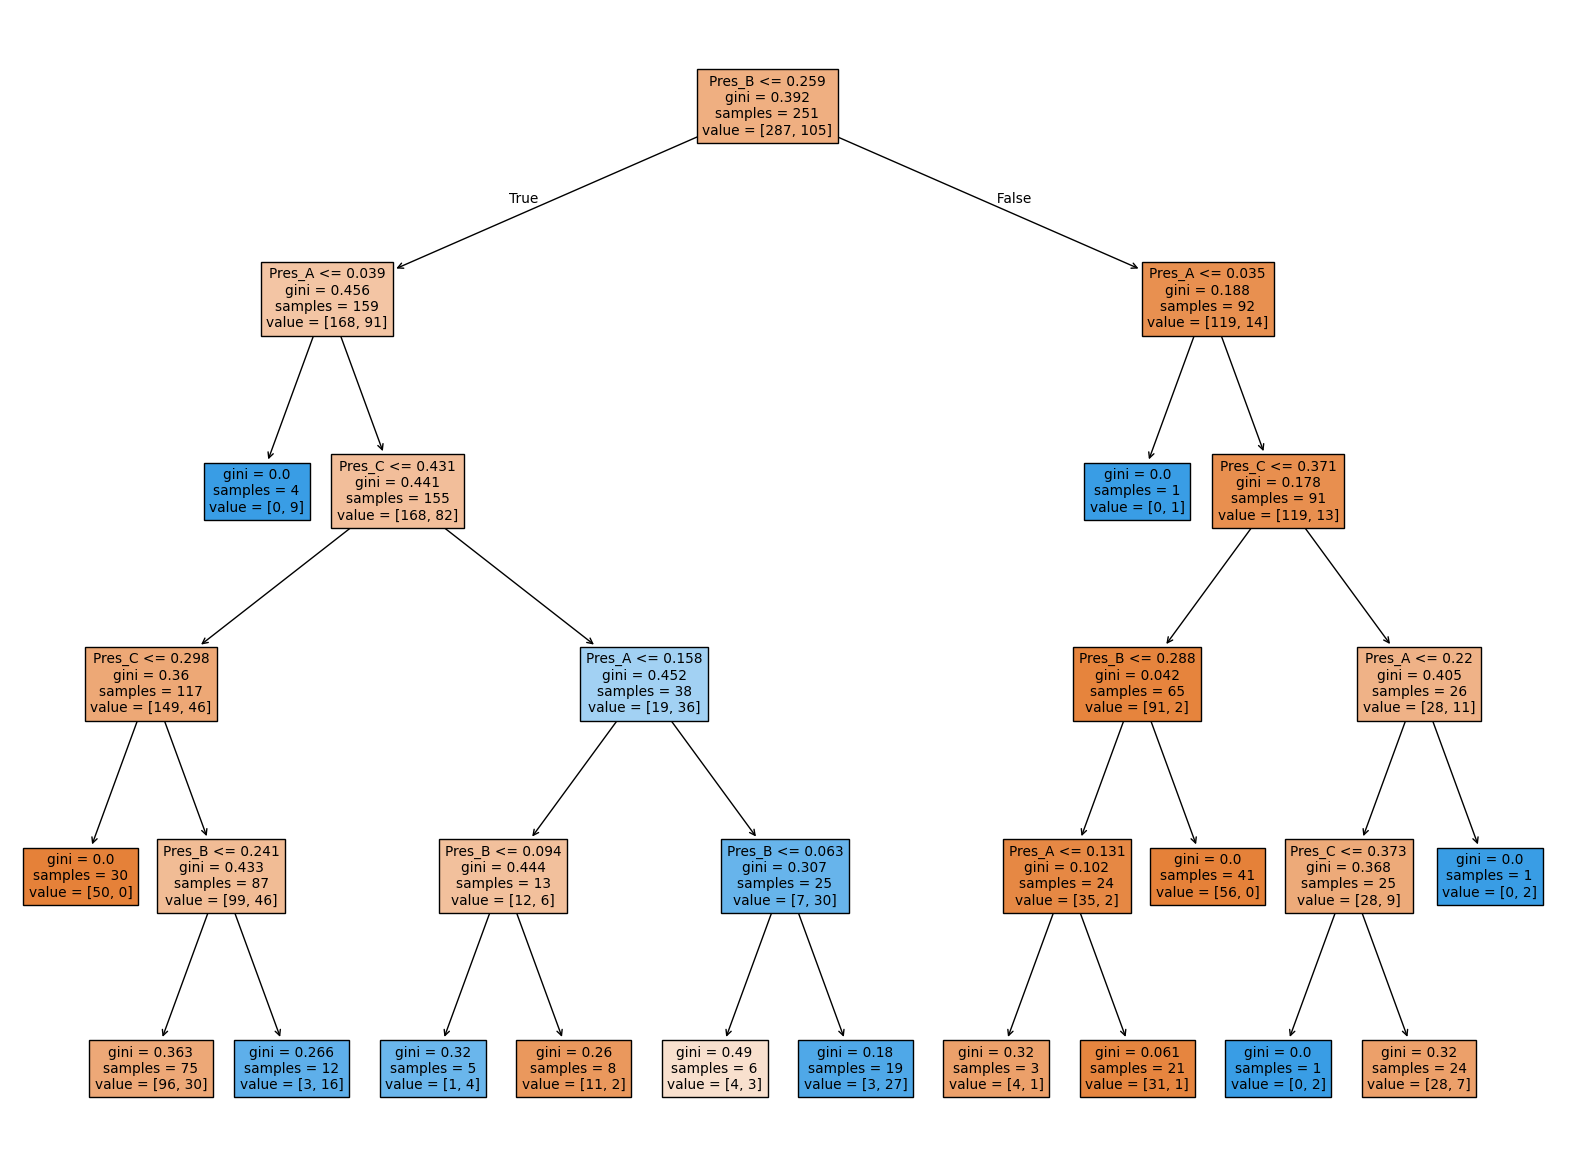

In [45]:
plt.figure(figsize = (20, 15))
plot_tree(rf.estimators_[1], filled = True, feature_names = ["Pres_A", "Pres_B", "Pres_C", "Pres_D"])
plt.show()

### 증거 1

- stripplot 시각화를 통해 Spoiled 여부에 따른 각 방부제 비율의 분포 확인

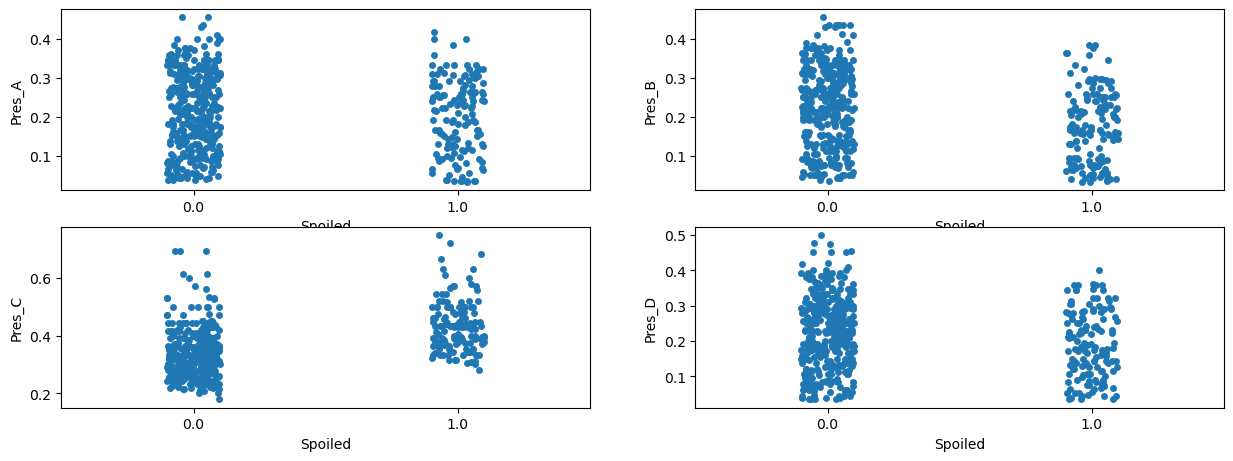

In [38]:
fig = plt.figure(figsize = (15, 8))
ax1 = fig.add_subplot(3, 2, 1)
ax2 = fig.add_subplot(3, 2, 2)
ax3 = fig.add_subplot(3, 2, 3)
ax4 = fig.add_subplot(3, 2, 4)

sns.stripplot(y = 'Pres_A', x = "Spoiled", data = df, ax = ax1)
sns.stripplot(y = 'Pres_B', x = "Spoiled", data = df, ax = ax2)
sns.stripplot(y = 'Pres_C', x = "Spoiled", data = df, ax = ax3)
sns.stripplot(y = 'Pres_D', x = "Spoiled", data = df, ax = ax4)

plt.show()

- 사료가 상한 경우 (Spoiled == 1)
    - 방부제 C가 높게 분포되어 있음
        - 방부제 C에 문제가 있어 사료가 상했을 가능성 높음 
    - 반면에 방부제 A, B, D는 비교적 낮게 분포되어 있고 분포 형태도 유사

### 증거 2

- 랜덤포레스트의 특성 중요도

In [398]:
rf.feature_importances_

array([0.20167254, 0.18303706, 0.46876839, 0.14652201])

- Pred_C 가 가장 높은 특성 중요도를 보여 사료를 상하게 하는 가장 큰 요인으로 보임
    - Pred_C 특성이 Spoiled 에 가장 큰 영향을 끼치는 중요한 피처인 건 알겠는데, 그래서 이걸로 Pred_C가 높을 때 사료를 상하게 하는 경향이 있다는 (양의 상관관계) 걸 보일 수 있나? 

### 증거3

- 각 방부제 비율과 Spoiled 의 상관관계

In [386]:
df.columns

Index(['A', 'B', 'C', 'D', 'Spoiled', 'total', 'Pres_A', 'Pres_B', 'Pres_C',
       'Pres_D'],
      dtype='object')

In [54]:
corr = df.loc[:, ["Spoiled", 'Pres_A', 'Pres_B', 'Pres_C', 'Pres_D']].corr()

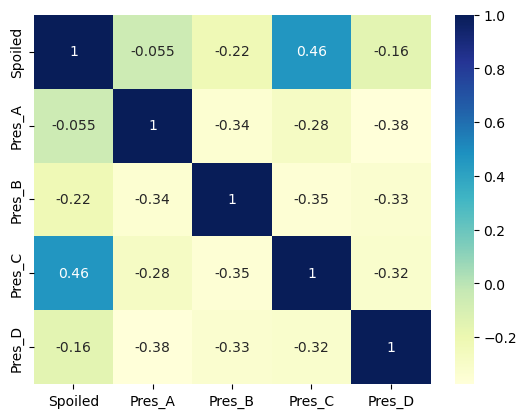

In [59]:
sns.heatmap(corr, annot = True, cbar = True, cmap = "YlGnBu")

plt.show()

- Pres_A, Pres_B, Pres_D 와 Spoiled 는 약한 음의 상관관계를 가짐

- 반면 Pres_C는 Spoiled 와 비교적 강한 양의 상관관계를 가짐
    - Pres_C의 비율이 높아지면 사료가 상하는 경향이 있음

### 증거 4

- 각 방부제 비율이 Spoiled 에 끼치는 영향의 정도를 확인하기 위해 로지스틱 회귀식 계수 비교

In [47]:
df.loc[:, ['Pres_A', 'Pres_B', 'Pres_C', 'Pres_D']].corr()

,Pres_A,Pres_B,Pres_C,Pres_D
Pres_A,1.000000,-0.339215,-0.284355,-0.376293
Pres_B,-0.339215,1.000000,-0.351889,-0.329374
Pres_C,-0.284355,-0.351889,1.000000,-0.317716
Pres_D,-0.376293,-0.329374,-0.317716,1.000000


- 피처 간 상관관계가 높지 않음

In [63]:
logi = LogisticRegression()
logi.fit(x_train, y_train)

LogisticRegression()

In [79]:
pred_proba_class1 = logi.predict_proba(x_test)[:, 1]
roc_auc_score(y_test, pred_proba_class1)

0.9035714285714286

In [64]:
logi.coef_

array([[-0.52575348, -1.81909335,  3.53014446, -1.18685134]])

- 회귀식의 각 피처의 계수를 확인해 보았을 때, Pres_C 의 계수만 양의 값을 가지고 절댓값도 가장 큼
    - 방부제 C의 비율이 높을 때 사료가 상하는 경향이 있음

### 증거 5

- statsmodels 라이브러리로 로지스틱 회귀 후 오즈비 확인

In [72]:
# statsmodels 라이브러리로 로지스틱 모델 학습
logi2 = sm.Logit(y_train, x_train)
result = logi2.fit()
result.summary()

Optimization terminated successfully.
         Current function value: 0.505173
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                Spoiled   No. Observations:                  392
Model:                          Logit   Df Residuals:                      388
Method:                           MLE   Df Model:                            3
Date:                Thu, 10 Apr 2025   Pseudo R-squ.:                  0.1556
Time:                        22:57:57   Log-Likelihood:                -198.03
converged:                       True   LL-Null:                       -234.52
Covariance Type:            nonrobust   LLR p-value:                 9.779e-16
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Pres_A        -3.7048      1.001     -3.700      0.000      -5.667      -1.742
Pres_B        -6.2790      1.056     -5.948      0.000      -8.348      -4.210
Pres_C         5.6677      0.912      6.215      0.000       3.880       7.455
Pres_D        -4.8832      1.011     -4.830      0.000      -6.865      -2.902
==============================================================================
"""

In [74]:
# 오즈비
np.exp(result.params)

Pres_A      0.024606
Pres_B      0.001875
Pres_C    289.354173
Pres_D      0.007572
dtype: float64

- 오즈비가 Pres_A, Pres_B, Pres_D는 아주 작은 반면 Pres_C의 값이 약 289.35로 매우 큼
    - 방부제 C를 사용하면 사용하지 않을 때보다 사료가 상할 확률이 289.35배 높다

### 증거 6

- 사료가 상했을 때 각 방부제의 평균 비율

In [49]:
spoiled_data = df[df["Spoiled"] == 1].mean()[["Pres_A", "Pres_B", "Pres_C", "Pres_D"]]

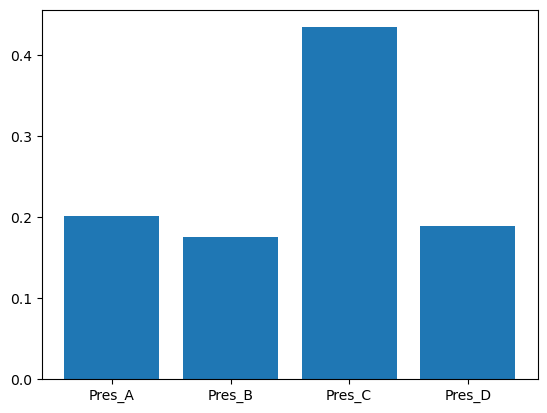

In [53]:
plt.bar(spoiled_data.index, spoiled_data.values)

plt.show()

- 사료가 상했을 때 Pres_A, Pres_B, Pres_D는 약 0.2 정도인 반면, Pres_C 는 0.4 가 넘는 값을 가짐
    - 통계검정으로 위의 평균 차이가 유의미한지 확인

In [84]:
df_pres =  df[df["Spoiled"] == 1][["Pres_A", "Pres_B", "Pres_C", "Pres_D"]]

In [85]:
df2 = pd.melt(df_pres)

In [92]:
# statsmodels 아노바 검정
model = ols("value ~ C(variable)", df2).fit()

In [95]:
anova_lm(model)

,df,sum_sq,mean_sq,F,PR(>F)
C(variable),3.0,6.403180,2.134393,248.396286,3.153435e-102
Residual,556.0,4.777538,0.008593,NaN,NaN


- pvalue 가 아주 작으므로 각 방부제 중 최소 하나의 집단은 통계적으로 유의미한 차이가 있음
    - 사후검정으로 짝지어 비교

In [96]:
posthoc = pairwise_tukeyhsd(df2["value"],
                            df2["variable"], 
                            alpha = 0.05)

In [97]:
print(posthoc)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
Pres_A Pres_B  -0.0259 0.0916 -0.0544  0.0027  False
Pres_A Pres_C   0.2333    0.0  0.2047  0.2618   True
Pres_A Pres_D  -0.0125 0.6745  -0.041  0.0161  False
Pres_B Pres_C   0.2591    0.0  0.2306  0.2877   True
Pres_B Pres_D   0.0134 0.6208 -0.0151   0.042  False
Pres_C Pres_D  -0.2457    0.0 -0.2743 -0.2172   True
----------------------------------------------------


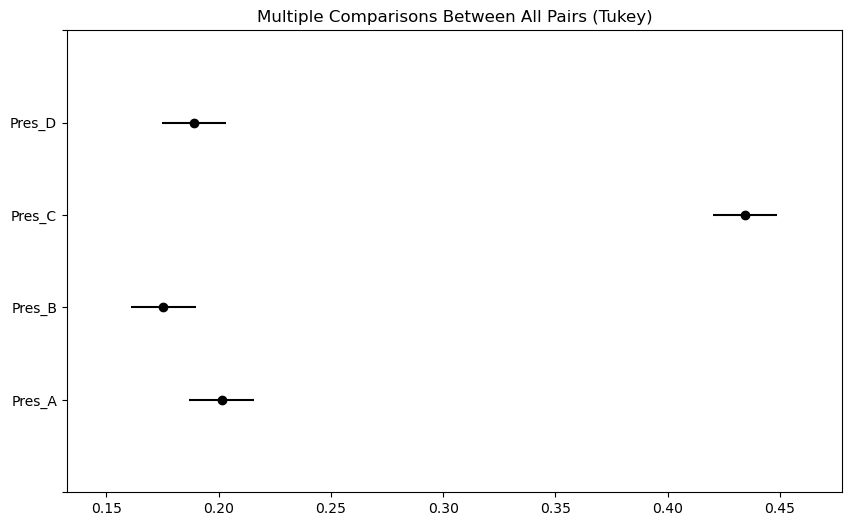

In [98]:
fig = posthoc.plot_simultaneous()

- Pres_C 와 다른 방부제 간 평균값 차이의 절댓값이 큼

- Pres_C 와 다른 방부제 간 평균값 차이의 p-value 가 0.0 으로 나오는 걸 보아 아주 작은 값으로 추정되며 통계적으로 매우 유의미한 차이가 있다는 걸 의미